### **1. Введение**
- **Что делает машинное обучение?**
    По статистическим закономерностям в доступной выборке делает предсказания о свойствах объекта из генеральной совокупности.


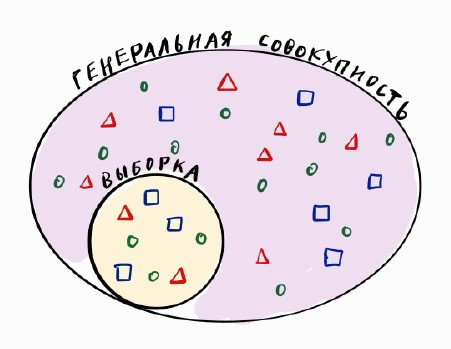



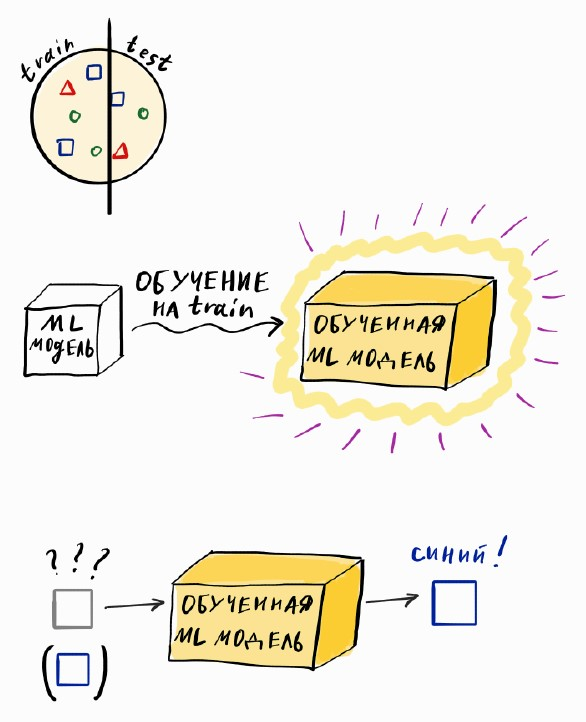

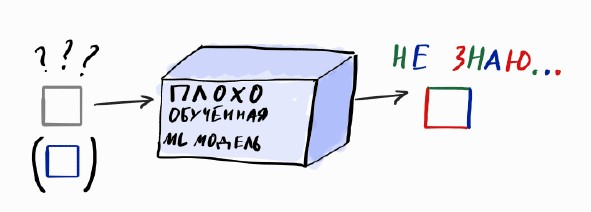

- **Что такое бинарная классификация?**  
    Краткое объяснение задачи: предсказание одного из двух классов.
    Пример: "Клиент вернет кредит?" (Да/Нет), "Транзакция мошенническая?" (Да/Нет).



- **Что такое метрика?**  
    Функция для оценки "качества" модели. Каждая метрика оценивает отдельный аспект в поведении модели.


- **Почему метрики важны?**
    Разные задачи и разные данные требуют разных способов оценивания качества. Одна и та же метрика на одной задаче и данных будет показывать осмысленную оценку качества, а на другой вводить в заблуждение.
    Пример: в антифроде критично не пропустить мошенничество, в кредитовании — клиентов нужно ранжировать от очень ненадёжных до очень надёжных. И то и другое - бинарная классификация, но цели у неё разные.


- **Причём здесь ранжирование?** Некоторые модели, обучаясь делать бинарную классификацию, автоматически учатся определять степень уверенности в принадлежности объекта к одному из двух классов. Это можно использовать для ранжирования объектов.

### **2. Confusion Matrix — основа понимания метрик**  

In [3]:
import random
random.seed(41)

y_true = [0]*100 + [1]*100
y_pred = [0 if (random.randint(0, 11) % 12) != 0 else 1  for _ in range(100)]+ [1 if (random.randint(0, 7) % 7) != 0 else 0 for _ in range(100)]

In [2]:
#%pip install scikit-learn

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
sns.set(font_scale=1.3)
conf_matrix = confusion_matrix(y_true, y_pred)
conf_matrix_annotation = [['TN', 'FN', 'FP', 'TP']]

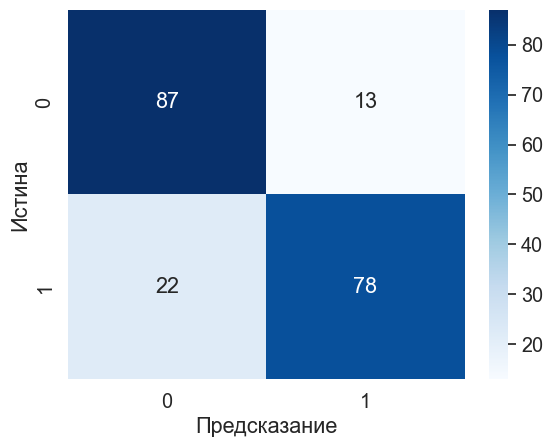

In [17]:
ax1 = sns.heatmap(conf_matrix, cmap='Blues', annot=True)
ax1.xaxis.set_label_text('Предсказание')
ax1.yaxis.set_label_text('Истина')
plt.show()

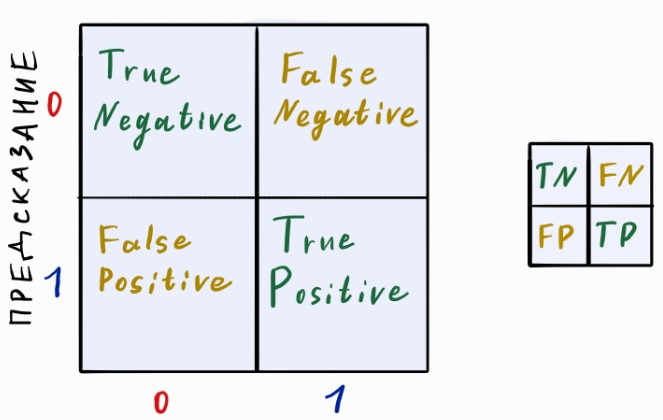

In [5]:
conf_matrix.ravel()

array([87, 13, 22, 78], dtype=int64)

In [6]:
tn, fp, fn, tp = conf_matrix.ravel()
print(tn, fp, fn, tp)

87 13 22 78


### **3. Основные метрики и их интерпретация**

#### **Accuracy**
$$
    Accuracy = \frac{TP+TN}{TP + TN + FP + FN}
$$
Словами: доля правильно классифицированных объектов среди всех объектов.

In [7]:
# Посчитаем руками
accuracy_manual = (tp + tn) / (tp + tn + fp + fn)
accuracy_manual

0.825

In [18]:
# Посчитаем accuracy с помощью sklearn
from sklearn.metrics import accuracy_score

accuracy_score(y_true, y_pred)

0.825

**Проблемы:**
- При дисбалансе классов показывает вводящие в заблуждение значения

    **Пример**: В антифроде 99% транзакций не являются мошенническими. Модель может просто классифицировать абсолютно все транзакции как немошеннические и её accuracy будет 99%.

- По значению нельзя понять, в чём именно модель ошибается.

    **Пример**: Модели могут неправильно классифицировать положительный класс или негативный и иметь одинаковый accuracy.

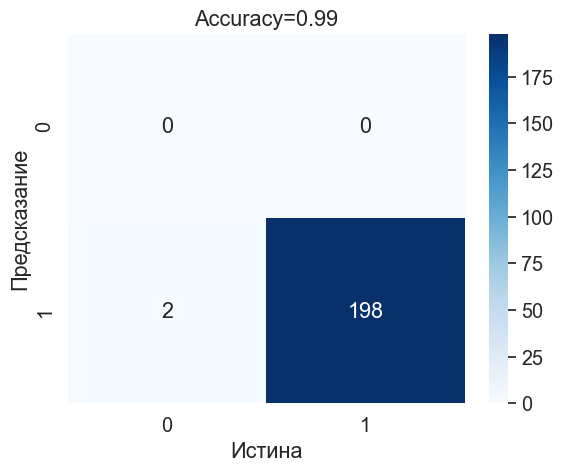

In [9]:
conf_matrix_99 = [[0, 0], [2, 198]]

ax1 = sns.heatmap(conf_matrix_99, cmap='Blues', annot=True, fmt='d')
ax1.set_title(f'Accuracy={198/200}')
ax1.xaxis.set_label_text('Истина')
ax1.yaxis.set_label_text('Предсказание')
plt.show()


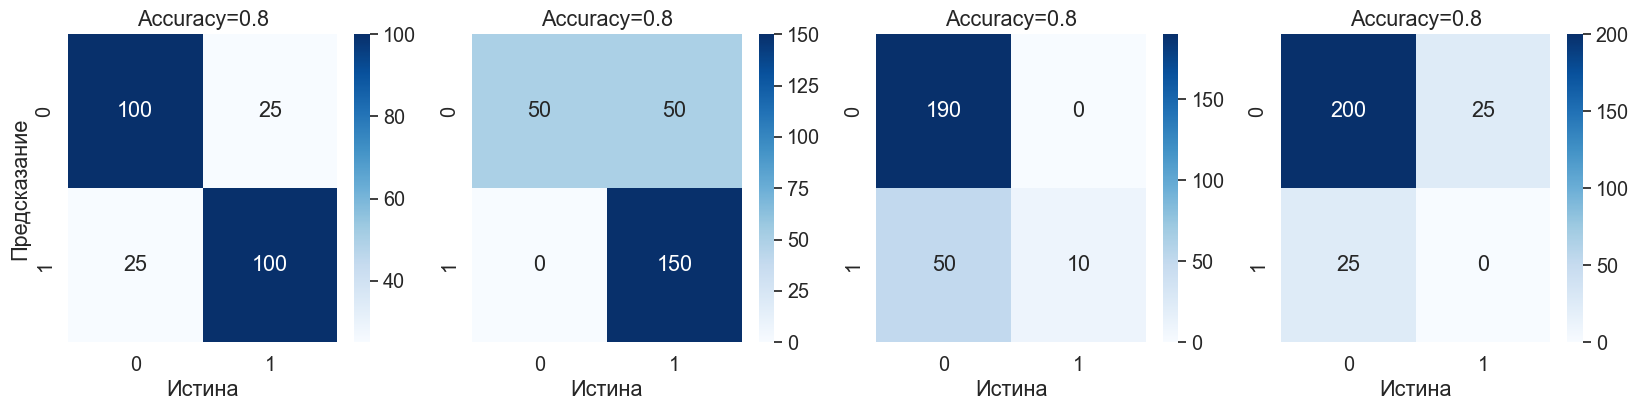

In [10]:
conf_matrix_bad_both =  [[100, 25], [25, 100]]
conf_matrix_bad_both_1 =  [[200, 25], [25, 0]]
conf_matrix_bad_fp = [[50, 50], [0, 150]]
conf_matrix_bad_fn = [[190, 0], [50, 10]]
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(20, 4),)
ax1 = sns.heatmap(conf_matrix_bad_both, cmap='Blues', annot=True, ax=ax1, fmt='d')
ax1.set_title(f'Accuracy={200/250}')
ax1.xaxis.set_label_text('Истина')
ax1.yaxis.set_label_text('Предсказание')
ax2 = sns.heatmap(conf_matrix_bad_fp, cmap='Blues', annot=True, ax=ax2, fmt='d')
ax2.set_title(f'Accuracy={200/250}')
ax2.xaxis.set_label_text('Истина')
ax3 = sns.heatmap(conf_matrix_bad_fn, cmap='Blues', annot=True, ax=ax3, fmt='d')
ax3.set_title(f'Accuracy={200/250}')
ax3.xaxis.set_label_text('Истина')
ax4 = sns.heatmap(conf_matrix_bad_both_1, cmap='Blues', annot=True, ax=ax4, fmt='d')
ax4.set_title(f'Accuracy={200/250}')
ax4.xaxis.set_label_text('Истина')

plt.show()

#### **Precision (Точность)**

$$
\frac{TP}{TP + FP}
$$

Доля правильно классифицированных объектов "положительного" класса среди всех объектов, которым был присвоен "положительный" класс.

**Интерпретация:** Насколько *точно* модель определяет положительный класс? Насколько мы можем верить, что объект, которому модель присвоила положительный класс, действительно принадлежит этому классу, насколько это заслуживающее доверия решение?

**Интуитивный пример:** определение спама. Важно не выбрасывать хорошие письма в спам - то есть, FP (ложная тревога) должно быть минимальным. Если же спам попадёт в ящик (FN), то это не такой плохой сценарий, как потеря важного письма.

Цель - как можно меньше "не спам" попадает в категорию "спам"

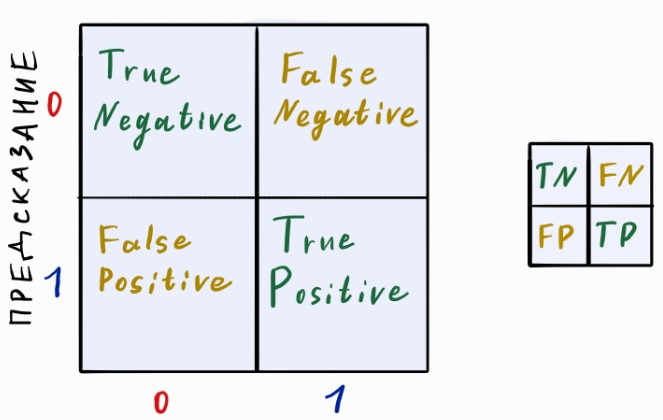

In [11]:
# Посчитаем руками
precision_manual = tp / (tp + fp)
precision_manual

0.8571428571428571

In [24]:
# Посчитаем accuracy с помощью sklearn
from sklearn.metrics import precision_score

precision_score(y_true, y_pred)

0.8571428571428571

**Проблемы:**
- Как видно из формулы, мы ничего не узнаем про TN и FN по метрике Precision.

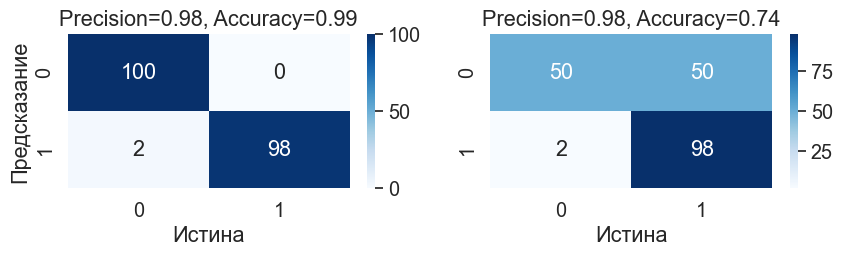

In [21]:
conf_matrix_bad_precision =  [[100, 0], [2, 98]]
conf_matrix_bad_precision_1 =  [[50, 50], [2, 98]]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 2),)
ax1 = sns.heatmap(conf_matrix_bad_precision, cmap='Blues', annot=True, ax=ax1, fmt='d')
ax1.set_title(f'Precision={98/(98+2)}, Accuracy={(100+98)/(200)}')
ax1.xaxis.set_label_text('Истина')
ax1.yaxis.set_label_text('Предсказание')
ax2 = sns.heatmap(conf_matrix_bad_precision_1, cmap='Blues', annot=True, ax=ax2, fmt='d')
ax2.set_title(f'Precision={98/(98+2)}, Accuracy={(50+98)/(200)}')
ax2.xaxis.set_label_text('Истина')

plt.show()

#### **Recall (Полнота)**

$$
\frac{TP}{TP + FN}
$$
**Словами:** доля корректно классифицированных объектов "положительного" класса среди всех объектов, которые действительно имеют "положительный" класс.

**Интерпретация:** "Какую долю всех объектов положительного класса мы смогли "отловить"? Насколько *полно* наша модель понимает свойства объекта положительного класса и может его обнаружить, не пропустив?"

**Инуитивный пример:** при обработке руды классифицировать золотоносные образцы. Цена пропуска золотоносного образца (ошибки FN) высока, намного выше, чем принятие пустого образца за золотоносный.

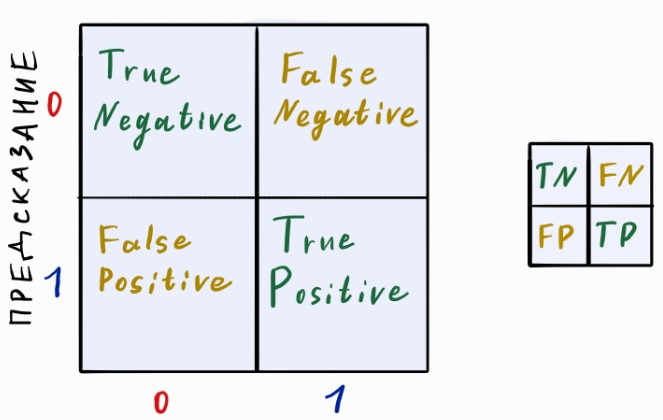

In [25]:
# Расчет Recall вручную
recall_manual = tp / (tp + fn)
print("Recall (ручной расчет):", recall_manual)

Recall (ручной расчет): 0.78


In [25]:
# Расчет Recall с помощью sklearn
from sklearn.metrics import recall_score
recall_sklearn = recall_score(y_true, y_pred)
print("Recall (sklearn):", recall_sklearn)

Recall (sklearn): 0.78


Проблемы:
- Как видно из формулы, метрика Recall никак не учитывает FP и TN.

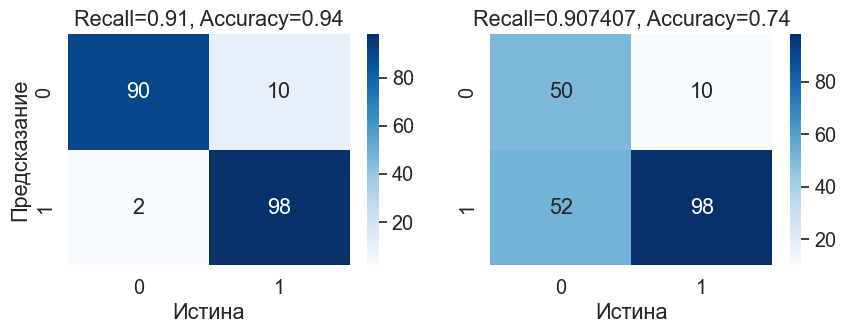

In [13]:
conf_matrix_bad_recall =  [[90, 10], [2, 98]]
conf_matrix_bad_recall_1 =  [[50, 10], [52, 98]]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3),)
ax1 = sns.heatmap(conf_matrix_bad_recall, cmap='Blues', annot=True, ax=ax1, fmt='d')
ax1.set_title(f'Recall={98/(98+10):.2f}, Accuracy={(90+98)/(200)}')
ax1.xaxis.set_label_text('Истина')
ax1.yaxis.set_label_text('Предсказание')
ax2 = sns.heatmap(conf_matrix_bad_recall_1, cmap='Blues', annot=True, ax=ax2, fmt='d')
ax2.set_title(f'Recall={98/(98+10):2f}, Accuracy={(50+98)/(200)}')
ax2.xaxis.set_label_text('Истина')

plt.show()

#### **F1**

$$
\frac{2*Precision*Recall}{Precision + Recall}
$$
Среднее гармоническое между Precision и Recall.

**Интерпретация:** Метрика, которая не может иметь высокое значение, если одна из составляющих (Recall или Precision) имеет низкое значение.

**Интуитивный пример:** тот же пример с добычей золота, но теперь проверка тоже не дешёвая и важно, чтобы модель и не пропускала золото, и как можно меньше давала ложных срабатываний.


In [27]:
# Расчет F1 вручную
f1_manual = 2 * (precision_manual * recall_manual) / (precision_manual + recall_manual)
print("F1-Score (ручной расчет):", f1_manual)

F1-Score (ручной расчет): 0.8167539267015708


In [15]:
# Расчет F1 с помощью sklearn
from sklearn.metrics import f1_score
f1_sklearn = f1_score(y_true, y_pred)
print("F1-Score (sklearn):", f1_sklearn)

F1-Score (sklearn): 0.8167539267015707


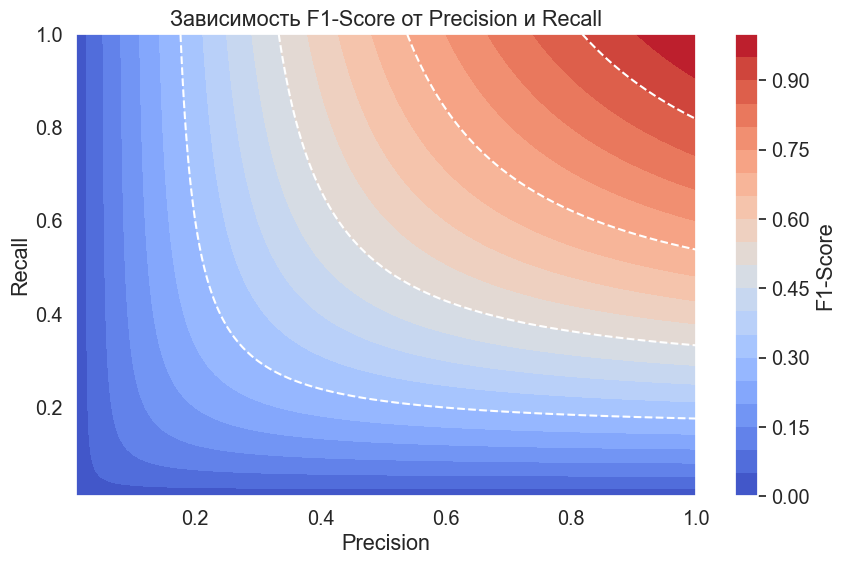

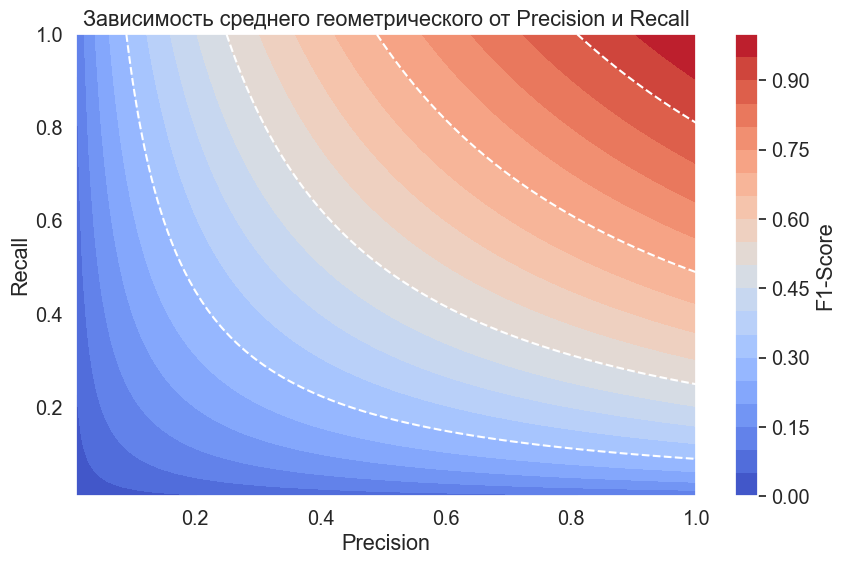

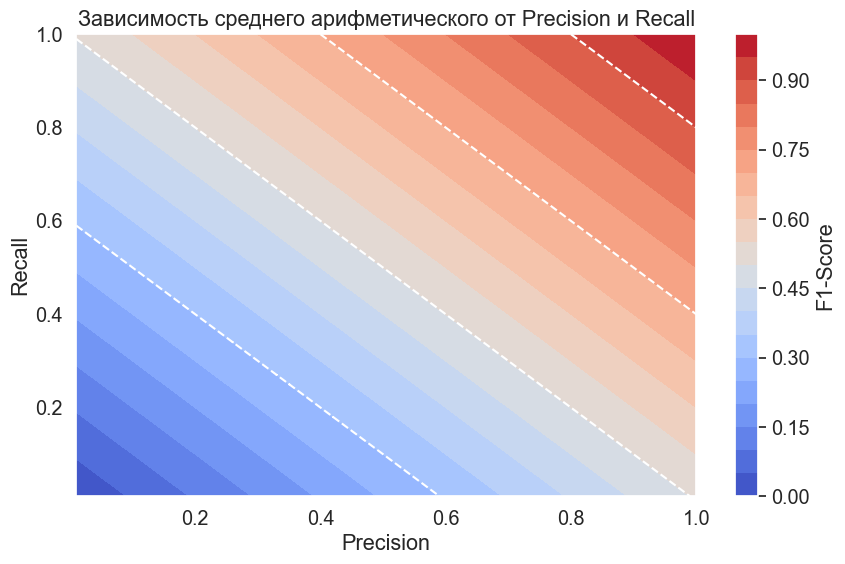

In [29]:
import numpy as np
import matplotlib.pyplot as plt

# Создаем сетку значений Precision и Recall
precision_values = np.linspace(0.01, 1, 100)
recall_values = np.linspace(0.01, 1, 100)
p, r = np.meshgrid(precision_values, recall_values)

# Формула F1
f1 = 2 * (p * r) / (p + r)

# Визуализация
plt.figure(figsize=(10, 6))
contour = plt.contourf(p, r, f1, levels=20, cmap='coolwarm')
plt.colorbar(contour, label='F1-Score')
plt.xlabel('Precision')
plt.ylabel('Recall')
plt.title('Зависимость F1-Score от Precision и Recall')

# Добавляем линии уровня для F1
plt.contour(p, r, f1, levels=[0.3, 0.5, 0.7, 0.9], colors='white', linestyles='dashed')

# Формула F1
f1 = (p * r)**(1/2)

# Визуализация
plt.figure(figsize=(10, 6))
contour = plt.contourf(p, r, f1, levels=20, cmap='coolwarm')
plt.colorbar(contour, label='F1-Score')
plt.xlabel('Precision')
plt.ylabel('Recall')
plt.title('Зависимость среднего геометрического от Precision и Recall')

# Добавляем линии уровня для F1
plt.contour(p, r, f1, levels=[0.3, 0.5, 0.7, 0.9], colors='white', linestyles='dashed')

# Формула F1
f1 = (p + r) / 2

# Визуализация
plt.figure(figsize=(10, 6))
contour = plt.contourf(p, r, f1, levels=20, cmap='coolwarm')
plt.colorbar(contour, label='F1-Score')
plt.xlabel('Precision')
plt.ylabel('Recall')
plt.title('Зависимость среднего арифметического от Precision и Recall')

# Добавляем линии уровня для F1
plt.contour(p, r, f1, levels=[0.3, 0.5, 0.7, 0.9], colors='white', linestyles='dashed')


plt.show()

#### **Precision-Recall Curve**
График значений Precision и Recall в зависимости от порога.
При идеальном предсказании график должен доходить до точки (1, 1), то есть, иметь precision=1 и recall=1.

Заметим, что TN вообще не участвует в рассчёте Precision и Recall. То есть, акцент делается на качестве выделения положительного класса.

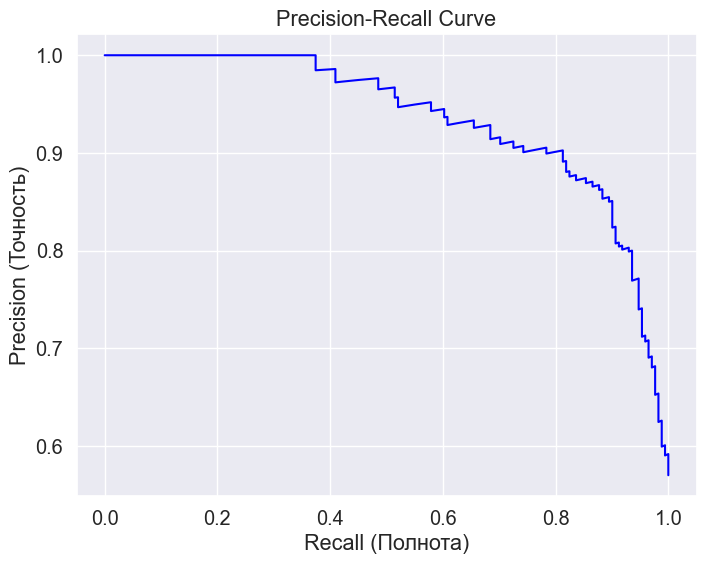

In [34]:
precision, recall, thresholds = precision_recall_curve(y_test, y_scores)

# Визуализация
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color='blue')
plt.xlabel('Recall (Полнота)')
plt.ylabel('Precision (Точность)')
plt.title('Precision-Recall Curve')
plt.grid(True)
plt.show()

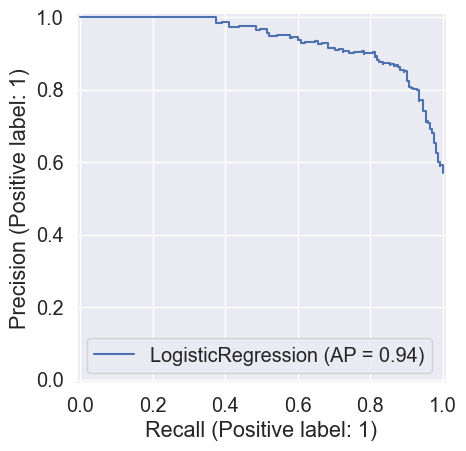

In [35]:
from sklearn.metrics import PrecisionRecallDisplay

display = PrecisionRecallDisplay.from_estimator(
    model, X_test, y_test, name="LogisticRegression", plot_chance_level=False, despine=True, drop_intermediate=True
)

#### **ROC кривая и ROC-AUC**

Формально это график между TPR и FPR:

**True Positive Rate (TPR)** = Recall = TP / (TP + FN) — доля верно предсказанных положительных примеров.

**False Positive Rate (FPR)** = FP / (FP + TN) — доля отрицательных примеров, ошибочно классифицированных как положительные.

При изменении порога классификации (от 0 до 1) вычисляются TPR и FPR.

Кривая соединяет точки (FPR, TPR) для всех порогов.

Однако есть более понятное объяснение построения графика.

Отранжируем полученные вероятности, рядом запишем настоящие значения и будем идти сверху вниз и смотреть на истинное значение. Если  истинное значение равно 1, то откладываем отрезок вверх, если не равно, то вправо.

Проверим себя:
- Если предсказание идеально правильное, то график будет идти строго вверх, затем строго вправо и иметь площадь 1.
- Если, наоборот, предсказание совершенно неверное, то график сначала будет идти строго вправо, затем строго вверх и иметь площадь 0. (А если инвертировать предсказания, заменив 0 на 1, а 1 на 0, то получим верные предсказания. То есть, если ROC-AUC меньше 0.5, то можно просто развернуть метки наоборот и получить модель более высокого качества).
- Если будем случайно предсказывать, то график будет идти около диагонали и иметь площадь 0.5.

Из принципа построения видно, что ROC-AUC одинаково учитывает качество предсказания обоих классов. Поэтому для кредитного скоринга данная метрика хорошо подходит - оценивает предсказание и лучших клиентов, и худших.

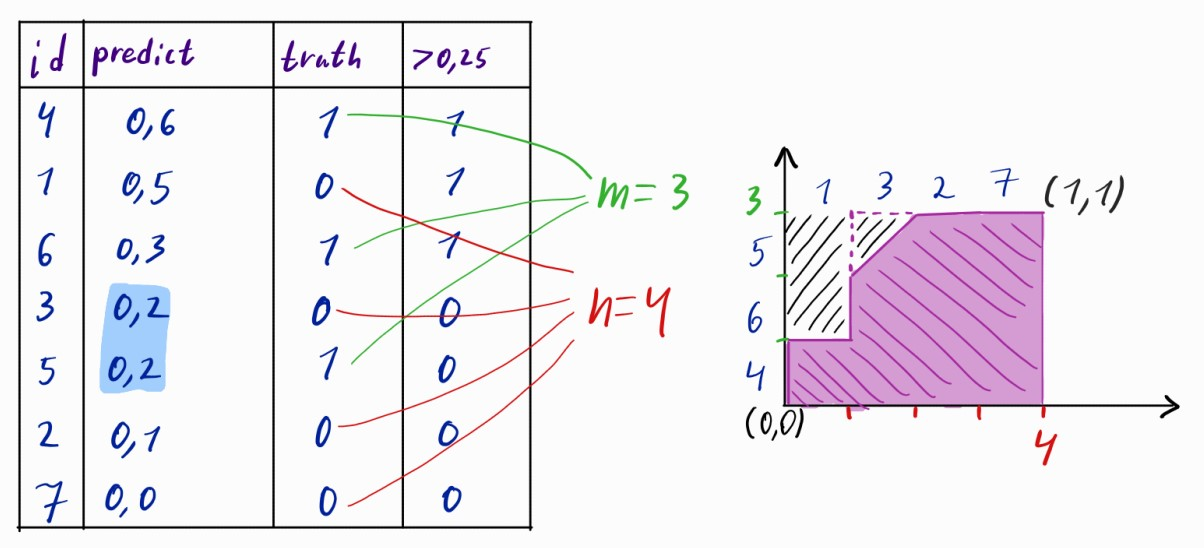

### Поменяем порог

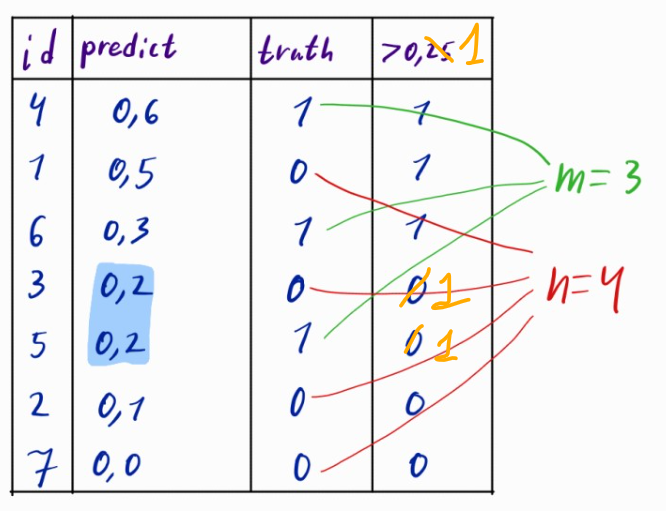

### Считаем Roc-auc

In [31]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, average_precision_score

In [32]:
# Создаём синтетические данные
X, y = make_classification(
    n_samples=1000,
    n_classes=2,
    weights=[0.45, 0.55],
    random_state=42
)

# Разделение на train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [33]:
model = LogisticRegression()
model.fit(X_train, y_train)

# Предсказание вероятностей для положительного класса
y_scores = model.predict_proba(X_test)[:, 1]  # берём вероятности класса "1"

In [34]:
# Построение ROC-кривой
from sklearn.metrics import roc_curve, roc_auc_score

In [35]:
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
roc_auc = roc_auc_score(y_test, y_scores)

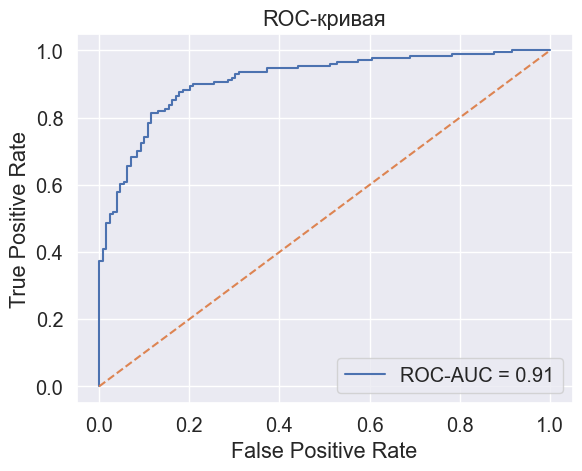

In [33]:
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.title("ROC-кривая")
plt.show()

### Коэффициент Джини (Gini coefficient)

Коэффициент Джини (Gini coefficient) — это метрика качества для оценки предсказательных моделей, особенно в задачах бинарной классификации. 
Полезен, когда классы в данных сильно несбалансированы (например, в кредитном скоринге: почти все клиенты надёжные, но есть и единичные дефолты).


Как это работает: коэффициент показывает, насколько хорошо модель умеет ранжировать объекты — то есть ставит «хороших» клиентов выше в списке, чем «плохих». Чем выше значение, тем лучше ранжирование. 

Иногда его связывают с ROC_AUC: 

Gini = 2 * ROC_AUC – 1 

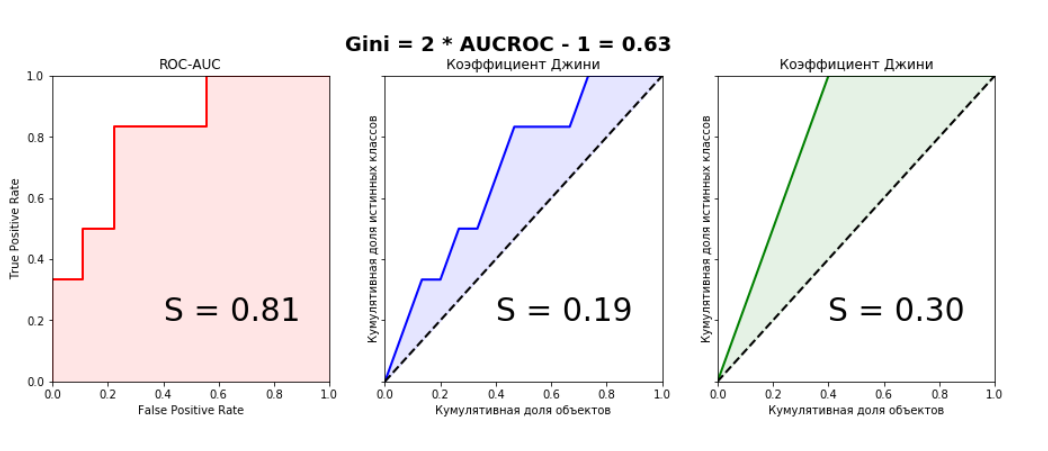

Как считаем: ранжируем предсказанные вероятности модели по убыванию и подставляем в формулу кумулятивную долю истинных значений целевой переменной, соответствующих предсказанным вероятностям

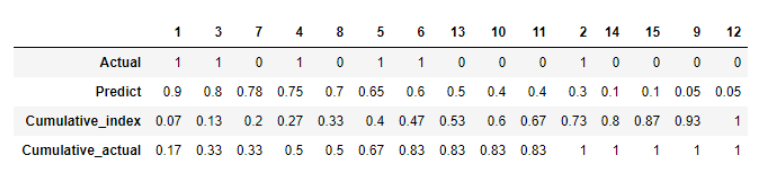

### Метрики при дисбалансе данных

In [44]:
y_true_unbalanced = [0]*180 + [1]*20
y_pred_unbalanced = [0 if (random.randint(0, 11) % 12) != 0 else 1  for _ in range(180)]+ [1 if (random.randint(0, 7) % 7) != 0 else 0 for _ in range(20)]

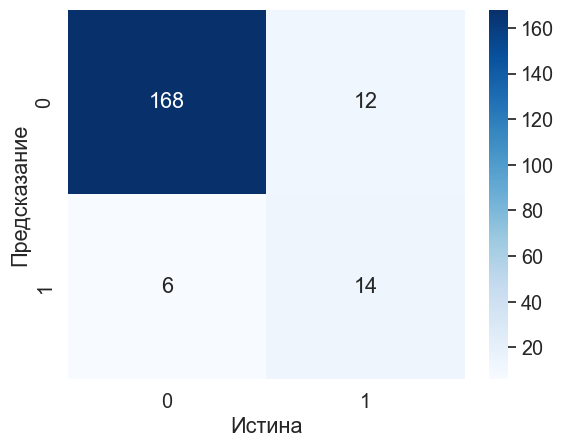

In [45]:
conf_matrix_unbalanced = confusion_matrix(y_true_unbalanced, y_pred_unbalanced)
ax1 = sns.heatmap(conf_matrix_unbalanced, cmap='Blues', annot=True, fmt='d')
ax1.xaxis.set_label_text('Истина')
ax1.yaxis.set_label_text('Предсказание')
plt.show()

In [46]:
accuracy_score(y_true_unbalanced, y_pred_unbalanced)

0.91

In [47]:
precision_score(y_true_unbalanced, y_pred_unbalanced)

0.5384615384615384

In [48]:
recall_score(y_true_unbalanced, y_pred_unbalanced)

0.7

In [49]:
f1_score(y_true_unbalanced, y_pred_unbalanced)

0.6086956521739131

In [50]:
fpr, tpr, thresholds = roc_curve(y_true_unbalanced, y_pred_unbalanced)
roc_auc = roc_auc_score(y_true_unbalanced, y_pred_unbalanced)

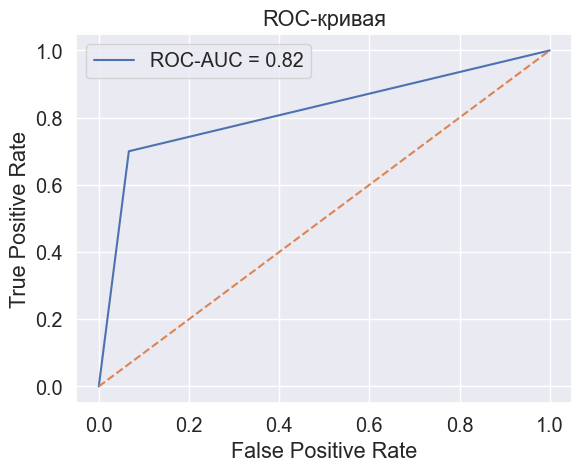

In [51]:
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.title("ROC-кривая")
plt.show()

### Balanced Accuracy

Метрика, которая используется для оценки качества моделей классификации в задачах с несбалансированными наборами данных. 
Она решает проблему традиционной метрики Accuracy, которая может давать завышенные оценки, если в данных сильно доминирует один класс

**Balanced Accuracy** = 1/2 × (**Sensitivity** + **Specificity**)
где:
**Sensitivity** (чувствительность, true positive rate) — доля правильно предсказанных положительных случаев среди всех реальных положительных:

**Sensitivity** = **TP** / (**TP** + **FN**)
    
**Specificity** (специфичность, true negative rate) — доля правильно предсказанных отрицательных случаев среди всех реальных отрицательных:

**Specificity** = **TN** / (**TN** + **FP**)

In [52]:
tn, fp, fn, tp = conf_matrix_unbalanced.ravel()
print(tn, fp, fn, tp)

168 12 6 14


In [53]:
sensitivity = tp / (tp + fn)
print("Sensitivity (ручной расчет):", sensitivity)
specificity = tn / (tn + fp)
print("Specificity (ручной расчет):", specificity)
balanced_accuracy = 1/2 * (sensitivity + specificity)
print("Balanced Accuracy (ручной расчет):", balanced_accuracy)

Sensitivity (ручной расчет): 0.7
Specificity (ручной расчет): 0.9333333333333333
Balanced Accuracy (ручной расчет): 0.8166666666666667


In [54]:
from sklearn.metrics import balanced_accuracy_score

balanced_accuracy_score(y_true_unbalanced, y_pred_unbalanced)

0.8166666666666667

### **Метрики регрессии**

MSE (Mean Squared Error) — средний квадрат разности между истинными и предсказанными значениями:

MSE = $\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$

*  $n$ - количество наблюдений
*  $y_i$ - истинное значение
*  $\hat{y}_i$ - предсказанное значение

Плюсы: 	Подчеркивает значительные ошибки сильнее, чем маленькие, благодаря квадрату разницы — это помогает выявить крупные промахи модели.

Минусы:	Из-за возведения в квадрат ошибка выражается в квадратичных единицах измерения, что затрудняет интерпретацию.

RMSE = $\sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$

Плюсы: Единицы измерения совпадают с исходными данными, что облегчает интерпретацию результата.

Минусы:	Наследует чувствительность к выбросам от MSE.

In [36]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error


y_true = np.array([3, -0.5, 2, 7])  
y_predicted = np.array([2.5, 0.0, 2, 8])  


mse = mean_squared_error(y_true, y_predicted)
print(f"MSE: {mse}")


rmse = np.sqrt(mse)  
print(f"RMSE: {rmse}")

MSE: 0.375
RMSE: 0.6123724356957945


# **Train-Val Split: Разделение данных для валидации**
Необходимо разделить данные на три части:  
- **Train set** (обучающий набор): используется для обучения модели.  
- **Validation set** (валидационный набор): используется для оценки качества модели **во время обучения** и настройки гиперпараметров.  
- **Test set** (тестовый набор): используется для финальной оценки качества модели **после обучения**.  


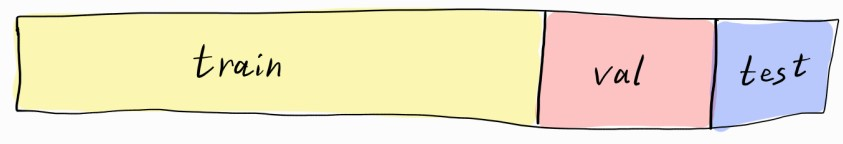

**Зачем это нужно?**  
- Чтобы избежать переобучения: модель не должна "видеть" валидационные данные в процессе обучения.
- Уменьшить риск переобучения при настройке гиперпараметров модели.

#### **Интуитивный пример**  
Представьте, что вы учитесь решать математические задачи:  
- **Train set** — учебник с примерами и решениями (на них вы тренируетесь).  
- **Validation set** — пробный экзамен (проверяете, насколько хорошо вы усвоили материал).
- **Test set** — реальный экзамен.

Если вы подгоните ответы под пробный экзамен - выучите их, найдёте какую-нибудь странную закономерность, то на реальном экзамене можете показать плохой результат.  

#### **Чем отличается Validation Set от Test Set**  
- **Validation set** — для настройки модели.  
- **Test set** — для финальной оценки **после** всех настроек.  

**Важно**: Никогда не используйте test set для принятия решений во время обучения!  

In [37]:
from sklearn.model_selection import train_test_split

# Создаем синтетические данные
X, y = np.random.rand(1000, 5), np.random.randint(0, 2, 1000)

# Разделение данных: 80% train, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,  # для воспроизводимости
    stratify=y  # сохраняет распределение классов
)

print(f"Размеры наборов:")
print(f"Train: {X_train.shape[0]} samples")
print(f"Validation: {X_val.shape[0]} samples")

Размеры наборов:
Train: 800 samples
Validation: 200 samples


In [38]:
# Полный цикл: Train -> Val -> Test
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.1)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.2)

print("\nИтоговые размеры:")
print(f"Train: {X_train.shape[0]}, Val: {X_val.shape[0]}, Test: {X_test.shape[0]}")


Итоговые размеры:
Train: 720, Val: 180, Test: 100


#### **Кросс-валидация**

Исходные данные многократно разбиваются на обучающую и валидационную части, чтобы и на каждом разбиении обучается модель. Это позволяет:

* Оценить стабильность модели.

* Настроить гиперпараметры.

* Проверить, как модель работает на разных подвыборках данных.

Кросс-валидация это про этап обучения (train + validation). Тестовая выборка точно так же остаётся нетронутой до самого конца для финального замера качества.

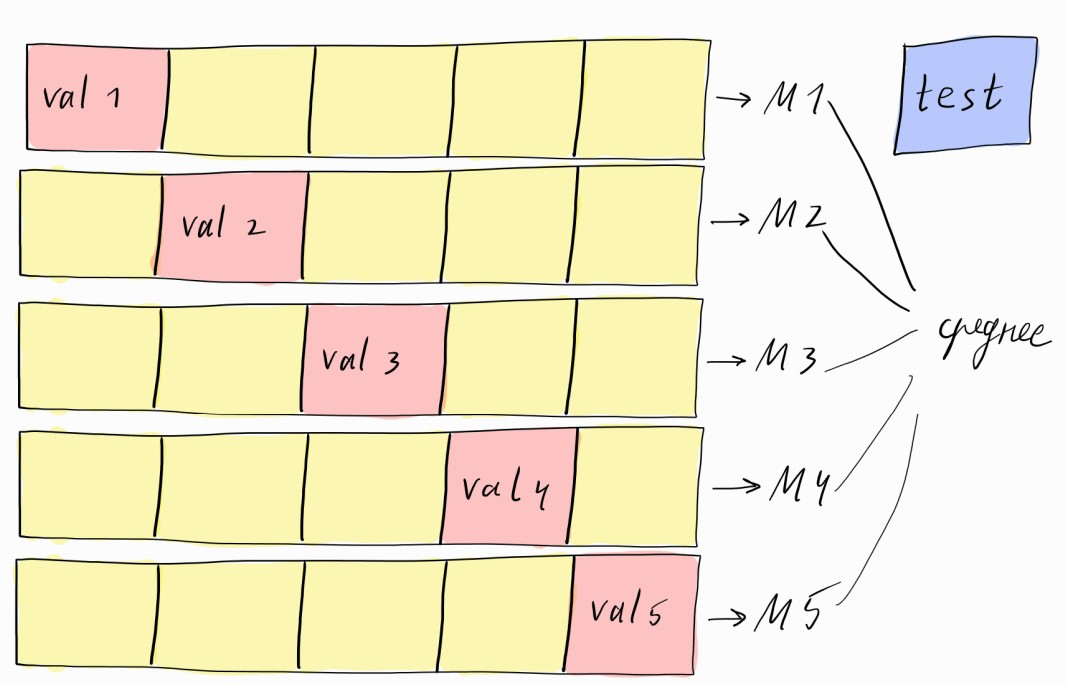

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
scores = cross_val_score(model, X, y, cv=5, scoring='f1')
print("F1 на 5 фолдах:", scores)
print("Средний F1:", np.mean(scores))

F1 на 5 фолдах: [0.48543689 0.52083333 0.46700508 0.50810811 0.53807107]
Средний F1: 0.5038908953554609


## **Когда какое разбиение использовать?**  
- **Много данных**: Однократное разделение достаточно из-за большого объема, то есть, подойдёт train-val split.  
- **Мало данные**: Лучше использовать кросс-валидацию.
- При любом разбиение финальная оценка производится на тестовой выборке, которая никак не участвует в обучении и настройке гиперпараметров модели.




## **А если временные ряды**  
- Обычный подход к кросс-валидации не работает в 99% случаев (и даже иногда не работает и на обычных данных)
- Нужно учесть влияние ранних данных на поздние




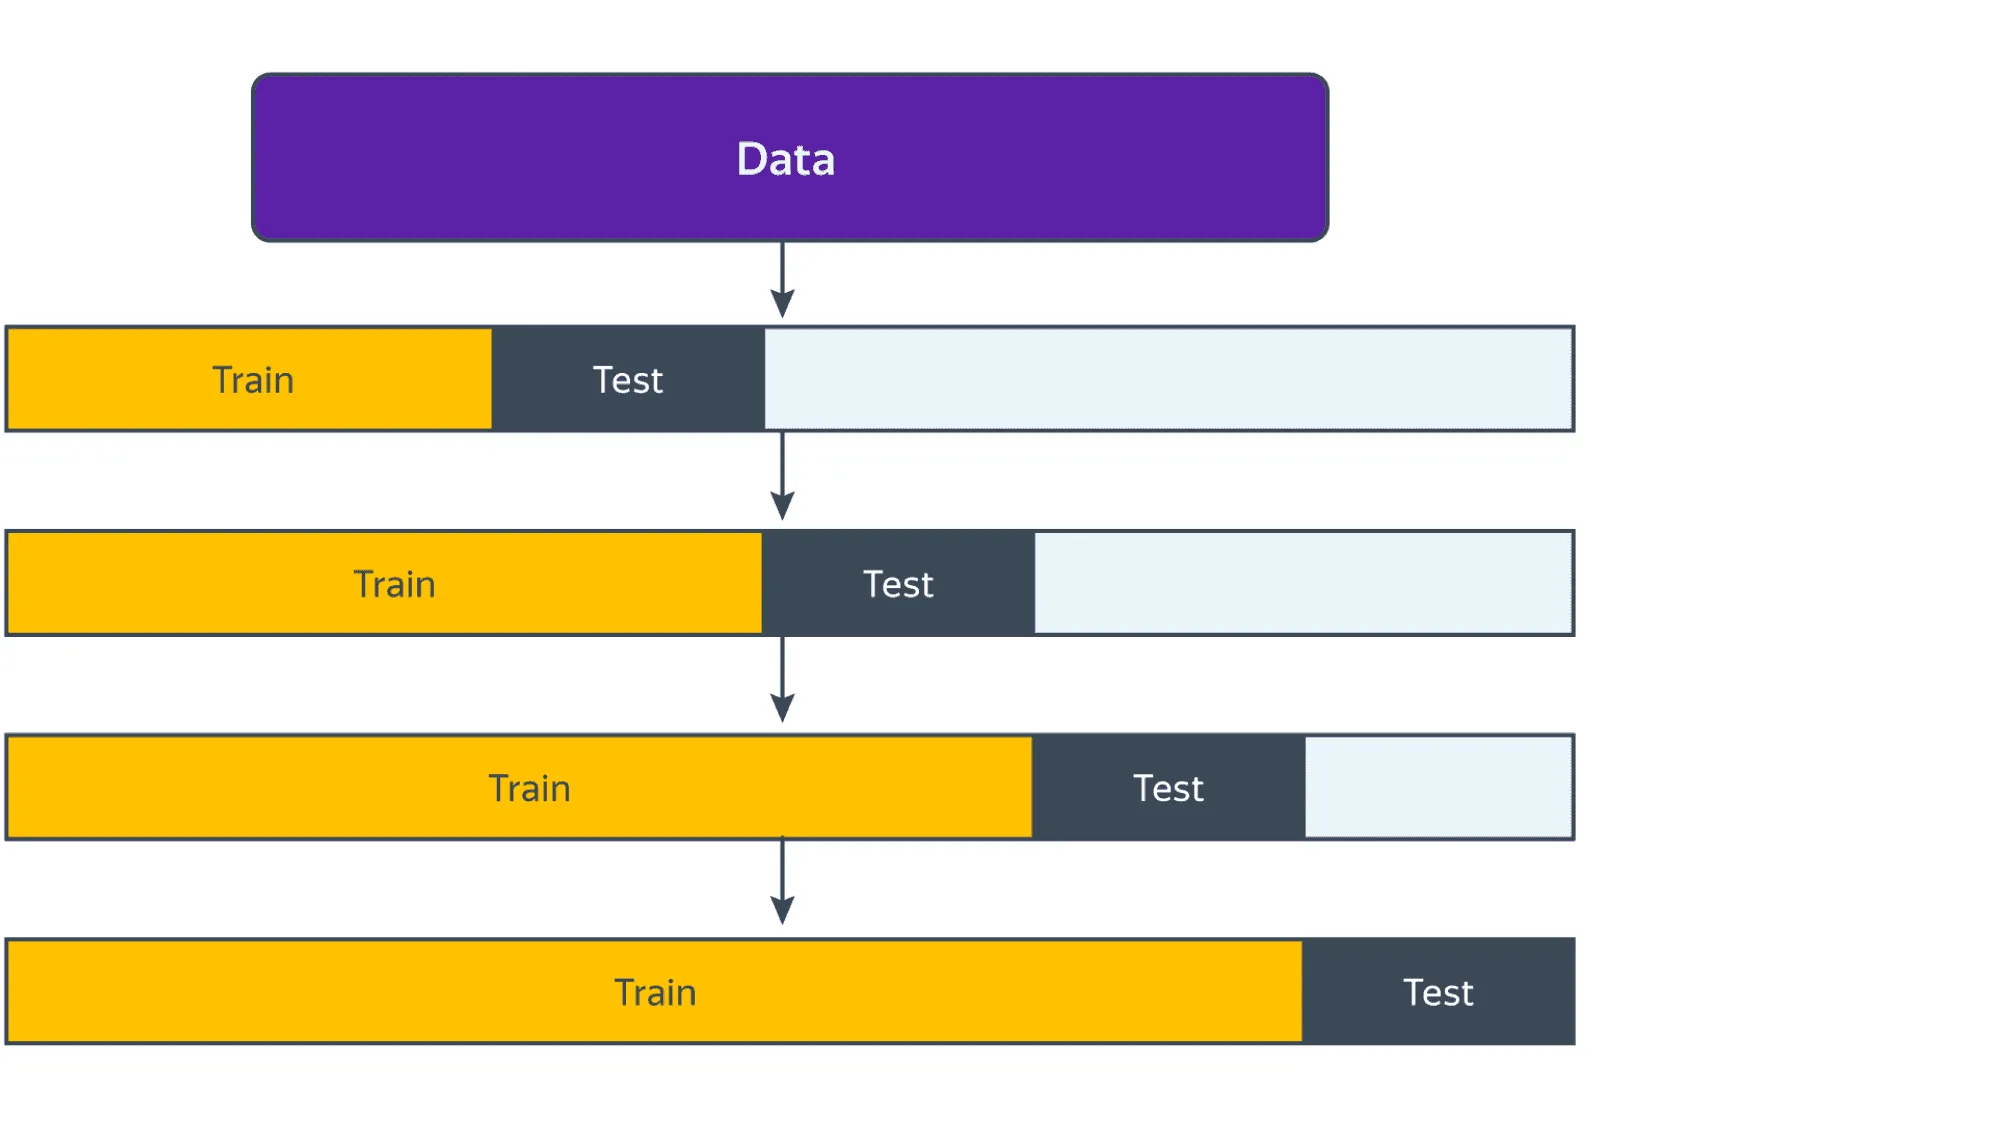

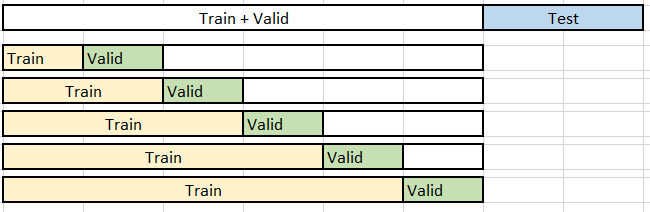

# **Вывод**  
  Нет универсальной метрики, выбор зависит от задачи, бизнес-целей и данных. Каждая метрика акцентируется на определённом свойстве в предсказаниях модели.